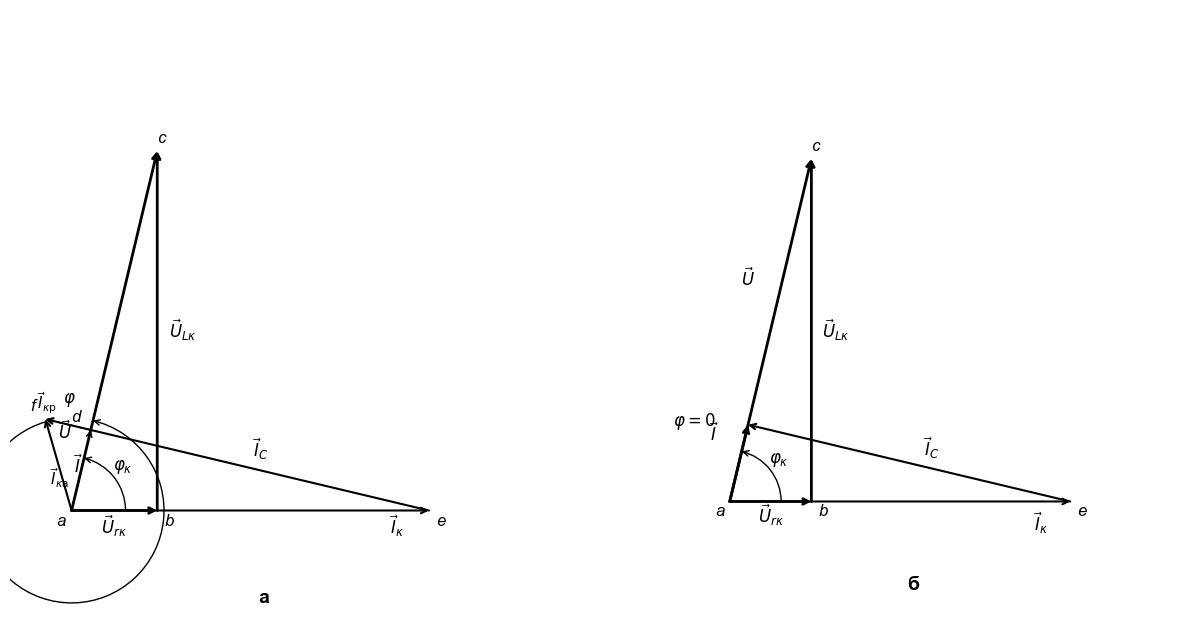

In [7]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

# Настройка шрифтов для корректного отображения греческих букв и индексов
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# Создаем фигуру, состоящую из двух графиков (1 строка, 2 колонки) на белом фоне
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 8), facecolor='white')
ax1.set_facecolor('white')
ax2.set_facecolor('white')

# =========================================================================
# ИСХОДНЫЕ ДАННЫЕ (Таблица 1 и Таблица 3, Опыт 3.3.1)
# =========================================================================
U_mag = 120.0   # Полное напряжение U
Ic_mag = 1.6    # Ток емкости Ic
Ik_mag = 1.45   # Ток катушки Ik
r_k = 19.0      # Активное сопротивление катушки
z_k = 82.0      # Полное сопротивление катушки

phi_k = np.arccos(r_k / z_k)  # Угол катушки ф_к

# Масштабные коэффициенты (чтобы напряжения и токи красиво сочетались)
scale_U = 0.04
scale_I = 3.2

# Функция для быстрого рисования стрелок-векторов
def draw_vector(ax, p1, p2, lw=1.5, ls='-'):
    ax.annotate('', xy=p2, xytext=p1,
                arrowprops=dict(arrowstyle="->", color="black", lw=lw, linestyle=ls, shrinkA=0, shrinkB=0))

# =========================================================================
# ГРАФИК А: Реальный эксперимент (сдвиг фаз общего тока присутствуют)
# =========================================================================
a1 = np.array([0.0, 0.0])
Urk_len = U_mag * (r_k / z_k) * scale_U
Ulk_len = U_mag * np.sin(phi_k) * scale_U

b1 = np.array([Urk_len, 0.0])
c1 = np.array([Urk_len, Ulk_len])
e1 = np.array([Ik_mag * scale_I, 0.0])

vec_U1 = c1 - a1
unit_U1 = vec_U1 / np.linalg.norm(vec_U1)
alpha_U1 = np.arctan2(unit_U1[1], unit_U1[0])
unit_N1 = np.array([-unit_U1[1], unit_U1[0]])

d1 = np.dot(e1, unit_U1) * unit_U1
f1 = e1 + unit_N1 * (Ic_mag * scale_I)
vec_I1 = f1 - a1
alpha_I1 = np.arctan2(vec_I1[1], vec_I1[0])

# Отрисовка векторов графика А
draw_vector(ax1, a1, b1, lw=2)
draw_vector(ax1, b1, c1, lw=2)
draw_vector(ax1, a1, c1, lw=2)
draw_vector(ax1, a1, e1, lw=1.5)
draw_vector(ax1, e1, f1, lw=1.5)
draw_vector(ax1, a1, f1, lw=1.5)
draw_vector(ax1, a1, d1, lw=1, ls='--')
draw_vector(ax1, d1, f1, lw=1, ls='--')

# Дуги и стрелки углов для графика А
arc_phi_k1 = patches.Arc(a1, width=1.4, height=1.4, angle=0, theta1=0, theta2=np.degrees(alpha_U1), color='black', lw=1)
ax1.add_patch(arc_phi_k1)
ax1.annotate('', xy=(0.7 * np.cos(alpha_U1), 0.7 * np.sin(alpha_U1)), xytext=(0.7 * np.cos(alpha_U1 - 0.05), 0.7 * np.sin(alpha_U1 - 0.05)),
            arrowprops=dict(arrowstyle="->", color="black", lw=1))

arc_phi1 = patches.Arc(a1, width=2.4, height=2.4, angle=0, theta1=np.degrees(alpha_I1), theta2=np.degrees(alpha_U1), color='black', lw=1)
ax1.add_patch(arc_phi1)
ax1.annotate('', xy=(1.2 * np.cos(alpha_U1), 1.2 * np.sin(alpha_U1)), xytext=(1.2 * np.cos(alpha_U1 - 0.05), 1.2 * np.sin(alpha_U1 - 0.05)),
            arrowprops=dict(arrowstyle="->", color="black", lw=1))

# Подписи векторов графика А
ax1.text(b1[0]/2, -0.3, r'$\vec{U}_{r\kappa}$', fontsize=12, ha='center')
ax1.text(b1[0] + 0.15, c1[1]/2, r'$\vec{U}_{L\kappa}$', fontsize=12, va='center')
ax1.text(d1[0]/2 - 0.3, d1[1]/2 + 0.4, r'$\vec{U}$', fontsize=12)
ax1.text(e1[0] - 0.5, -0.3, r'$\vec{I}_\kappa$', fontsize=12)
ax1.text((e1[0]+f1[0])/2 + 0.2, (e1[1]+f1[1])/2 + 0.1, r'$\vec{I}_C$', fontsize=12)
ax1.text(f1[0]/2 + 0.2, f1[1]/2 - 0.1, r'$\vec{I}$', fontsize=12)
ax1.text(d1[0]/2 - 0.4, d1[1]/2 - 0.2, r'$\vec{I}_{\kappa\text{а}}$', fontsize=11)
ax1.text((d1[0]+f1[0])/2 - 0.4, (d1[1]+f1[1])/2 + 0.2, r'$\vec{I}_{\kappa\text{р}}$', fontsize=11)

# Буквы вершин для графика А
ax1.text(a1[0] - 0.2, a1[1] - 0.2, 'a', fontsize=12, style='italic')
ax1.text(b1[0] + 0.1, b1[1] - 0.2, 'b', fontsize=12, style='italic')
ax1.text(c1[0], c1[1] + 0.1, 'c', fontsize=12, style='italic')
ax1.text(d1[0] - 0.25, d1[1] + 0.1, 'd', fontsize=12, style='italic')
ax1.text(e1[0] + 0.1, e1[1] - 0.2, 'e', fontsize=12, style='italic')
ax1.text(f1[0] - 0.2, f1[1] + 0.1, 'f', fontsize=12, style='italic')

# Подписи углов для графика А
ax1.text(0.85 * np.cos(alpha_U1 / 2), 0.85 * np.sin(alpha_U1 / 2), r'$\varphi_\kappa$', fontsize=12, ha='center')
ax1.text(1.4 * np.cos((alpha_U1 + alpha_I1) / 2), 1.4 * np.sin((alpha_U1 + alpha_I1) / 2), r'$\varphi$', fontsize=12, ha='center')
ax1.text(2.5, -1.2, 'а', fontsize=14, fontweight='bold', ha='center')

# Настройка осей А
ax1.axis('off')
ax1.set_aspect('equal')
ax1.set_xlim(-0.8, 6.0)
ax1.set_ylim(-1.5, 6.5)


# =========================================================================
# ГРАФИК Б: Полный резонанс токов (угол ф = 0, вектор тока I лежит на U)
# =========================================================================
a2 = np.array([0.0, 0.0])
b2 = np.array([Urk_len, 0.0])
c2 = np.array([Urk_len, Ulk_len])
e2 = np.array([Ik_mag * scale_I, 0.0])

vec_U2 = c2 - a2
unit_U2 = vec_U2 / np.linalg.norm(vec_U2)
alpha_U2 = np.arctan2(unit_U2[1], unit_U2[0])
unit_N2 = np.array([-unit_U2[1], unit_U2[0]])

d2 = np.dot(e2, unit_U2) * unit_U2
f2 = d2  # При резонансе f совпадает с d

# Отрисовка векторов графика Б
draw_vector(ax2, a2, b2, lw=2)
draw_vector(ax2, b2, c2, lw=2)
draw_vector(ax2, a2, c2, lw=2)
draw_vector(ax2, a2, e2, lw=1.5)
draw_vector(ax2, e2, f2, lw=1.5)
draw_vector(ax2, a2, f2, lw=2.0)

# Дуги и стрелки углов для графика Б
arc_phi_k2 = patches.Arc(a2, width=1.4, height=1.4, angle=0, theta1=0, theta2=np.degrees(alpha_U2), color='black', lw=1)
ax2.add_patch(arc_phi_k2)
ax2.annotate('', xy=(0.7 * np.cos(alpha_U2), 0.7 * np.sin(alpha_U2)), xytext=(0.7 * np.cos(alpha_U2 - 0.05), 0.7 * np.sin(alpha_U2 - 0.05)),
            arrowprops=dict(arrowstyle="->", color="black", lw=1))

# Подписи векторов графика Б
ax2.text(b2[0]/2, -0.3, r'$\vec{U}_{r\kappa}$', fontsize=12, ha='center')
ax2.text(b2[0] + 0.15, c2[1]/2, r'$\vec{U}_{L\kappa}$', fontsize=12, va='center')
ax2.text(c2[0]/2 - 0.4, c2[1]/2 + 0.6, r'$\vec{U}$', fontsize=12)
ax2.text(e2[0] - 0.5, -0.4, r'$\vec{I}_\kappa$', fontsize=12)
ax2.text((e2[0]+f2[0])/2 + 0.2, (e2[1]+f2[1])/2 + 0.1, r'$\vec{I}_C$', fontsize=12)
ax2.text(f2[0]/2 - 0.4, f2[1]/2 + 0.3, r'$\vec{I}$', fontsize=12)

# Подпись ф = 0
ax2.text(f2[0]/2 - 0.9, f2[1]/2 + 0.5, r'$\varphi = 0$', fontsize=12)

# Буквы вершин для графика Б
ax2.text(a2[0] - 0.2, a2[1] - 0.2, 'a', fontsize=12, style='italic')
ax2.text(b2[0] + 0.1, b2[1] - 0.2, 'b', fontsize=12, style='italic')
ax2.text(c2[0], c2[1] + 0.1, 'c', fontsize=12, style='italic')
ax2.text(e2[0] + 0.1, e2[1] - 0.2, 'e', fontsize=12, style='italic')

ax2.text(0.85 * np.cos(alpha_U2 / 2), 0.85 * np.sin(alpha_U2 / 2), r'$\varphi_\kappa$', fontsize=12, ha='center')
ax2.text(2.5, -1.2, 'б', fontsize=14, fontweight='bold', ha='center')

# Настройка осей Б
ax2.axis('off')
ax2.set_aspect('equal')
ax2.set_xlim(-1.2, 6.0)
ax2.set_ylim(-1.5, 6.5)

plt.show()
